## Pegasus Evaluation: Evidence per Service

Sections B.2 and B.2b of the evaluation of the paper. The evaluation is split into `2a_base_case.ipynb` (A, B.1), `2b_evidence.ipynb` (B.2, B.2b), `2c_depth_and_load.ipynb` (B.3, B.4), `2d_tails_and_percentiles.ipynb` (B.5, B.6) and `2e_iterative.ipynb` (C.1, C.2). `2a_base_case.ipynb` describes
the two data sources, the setup (A) and the metrics and methods (B.1) that every notebook uses; the parameters are
defined once in `pegasus/evaluation_setup.py`. Choose the data source with `data_source` in the first code cell.

In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
globals().update(configure(data_source))
# the base case of B.1 that this notebook builds on: read from statics/evaluation_cache/ (written by 2a_base_case.ipynb), or
# computed here if the cache is missing or stale (b1_base)
globals().update(b1_base(data_source))
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {n_train} training configurations per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

base case of B.1 loaded from statics\evaluation_cache\b1_real_c2f353971de3b326.joblib
real data, 3 seeds: chain detector -> transformer -> compressor, per seed 25 training configurations per service and 99 held-out configurations, poisson arrivals at one rate per configuration (1.58 to 65/s)


## B. Coverage and Tightness of Service Bounds

The metrics, the methods and the rule *validity before tightness* are those of B.1 (`2a_base_case.ipynb`).

### B.2 Varying Evidence per Service

- **Synthetic:** by varying the number of training configurations per service. The simulator cannot test the
  transfer between compositions, because a service's execution time does not depend on the chain there.
- **Real:** by varying the number of training runs, drawn from the benchmark runs of every service (see Training
  data in B.1); the largest number, `n_pool`, is the most that every service of the chain has. A training configuration is one run with its mean and its
  spread, so more evidence means more runs, not more items per run.
- **Baselines:** as in B.1 without DNN Sum (see Methods in B.1), each with the same training data as the
  proposed method.


**Setting.** For every seed, the chain, the held-out configurations and the ground truth of B.1. Only the
training data changes: `evidence_sizes` training configurations per service, drawn anew for every size
and seed. With real data, a training configuration is one *training run* of a service: the figure and the conclusion
count training runs. They are benchmark runs, never a run of the chain. With synthetic data,
no held-out configuration occurs in any of them. Conformal sets aside the same share of its configurations
for calibration as in B.1, and at least 19, the fewest that give it a finite bound; it is left out where fewer than 5
configurations would remain to train its model. The Oracle uses no training data.

**Complexity (against the amount of training data).** Training time and evaluation time are defined in B.1
(Metrics). With $n$ training configurations per service, training a GP costs on the order of $n^3$ operations per step
of its hyperparameter search, because every step factorizes an $n \times n$ matrix; the training time of every method
is therefore expected to grow with $n$, and faster than linearly for large $n$. A prediction of a trained GP at one
held-out configuration costs on the order of $n$ operations for the mean and $n^2$ for the variance. The evaluation
time contains these predictions and the computation of the bound from them, which does not depend on $n$; the
evaluation time is therefore expected to stay far below the training time, and to grow with $n$ only for the methods
whose evaluation consists mostly of GP predictions. The complexity against the depth
of the application is analyzed in B.3.

**Figures.** Three separate figures, each with the number of training configurations per service on the horizontal
axis (logarithmic). Every line is the median over the seeds, and the band around it reaches from the smallest to the largest seed; the
legend of every figure sits inside it where it hides the fewest points.
- *Tightness*, for every seed the median over its held-out configurations. The horizontal line at 1× is the measured
  quantile; in the red area below it a method is under the measured quantile and is no bound. A filled marker means
  that the method holds at that number of training configurations (it reaches the confidence level under every seed,
  as defined in B.1), and a hollow marker that it does not. Conformal has no point where it is left out. Look at the
  markers first: only lines with filled markers are bounds whose tightness can be compared.
- *Training time* (s, logarithmic), one line per set of trained models; the legend names the methods that use these
  models.
- *Evaluation time* (s, logarithmic), one line per method.

The figures are also saved as `figures/tsc/b2_evidence_<data source>_tightness.pdf`, `_training.pdf` and
`_evaluation.pdf`, each with a `.jpg`.

In [2]:
# B.2: the chains of B.1 with training data of different sizes
evidence_sizes = [10, 15, 25, n_pool] if data_source == "real" else [10, 15, 25, 50, 100, 200]   # training configurations per service; real: at most the pool
calibration_share = n_calibration / n_train             # share that Conformal sets aside for calibration, as in B.1


def compute():
    evidence, evidence_seconds = {}, {}                 # (size, seed) -> name -> (group, latency per held-out configuration) / (training time, evaluation time) in s
    with warnings.catch_warnings():
        # with few training configurations the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for size in evidence_sizes:
            for s in seeds:
                data = with_training_data(data_source, bases[s], n_train=size, seed=[seed, s, size], **training_options(s))
                assert_unseen(data)
                models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                evidence[(size, s)], evidence_seconds[(size, s)] = compare_methods(
                    data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration=max(19, round(calibration_share * size)),
                    model_seed=seed + s, leave_out=only_base_case, x_train_load=data.x_train_load)
    return dict(evidence=evidence, evidence_seconds=evidence_seconds)


globals().update(cached("b2_evidence", data_source, compute, inputs=dict(evidence_sizes=evidence_sizes, calibration_share=calibration_share)))
print(f"{len(evidence)} training sets evaluated.")

b2_evidence: results loaded from statics\evaluation_cache\b2_evidence_real_8e4153efef62b20e.joblib
12 training sets evaluated.


B.2 evidence per service, real data: detector → transformer → compressor, 99 held-out configurations per seed, poisson arrivals at one rate per configuration (1.58 to 65/s), 3 seeds


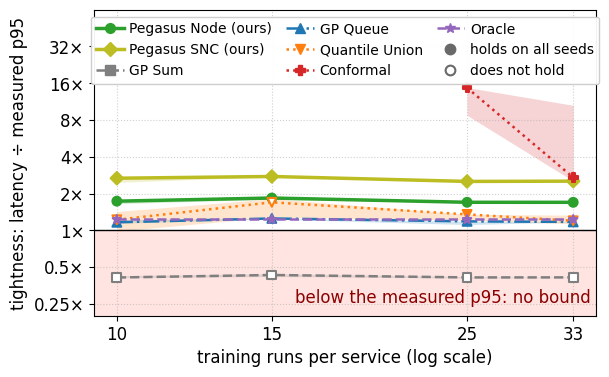

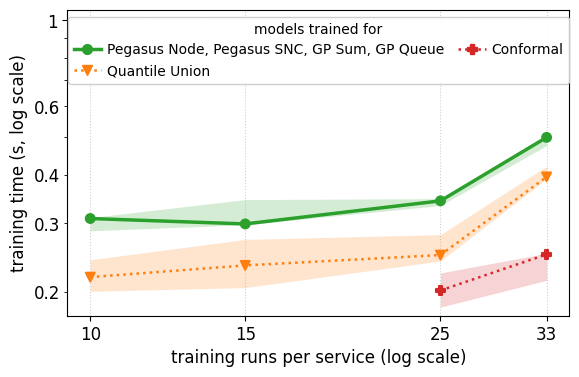

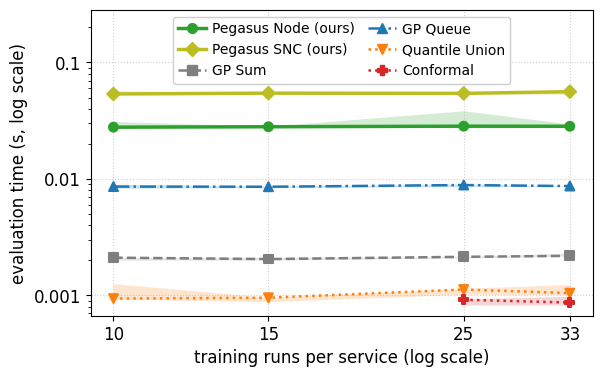

In [3]:
# B.2: coverage, tightness and times per number of training configurations; the ground truth is that of B.1 at every number
# with real data a training configuration is one run of a service, with the mean and the spread of its processing times
training_unit = "training runs" if data_source == "real" else "training configurations"
evidence_truth = {(size, s): (bases[s].measured, bases[s].measured_low) for size in evidence_sizes for s in seeds}
evidence_statistics = sweep_statistics(evidence, evidence_truth, evidence_sizes, seeds, confidence)   # name -> coverage, tightness, holds, computed
evidence_times = sweep_seconds(evidence_seconds, evidence_sizes, seeds)                                # name -> training, evaluation
tightness_and_time_figure(evidence_sizes, evidence_statistics, evidence_times, f"{training_unit} per service (log scale)",
                          f"B.2 evidence per service, {data_source} data: {' → '.join(base.path)}, {len(base.measured)} held-out configurations per seed, "
                          f"{arrivals}, {len(seeds)} seeds", p_label, name=f"b2_evidence_{data_source}")

In [4]:
size_label = lambda size: f"{size} {training_unit}"
display(Markdown(
    f"**What this shows** ({data_source} data, {arrivals}, ε = {alpha:g}, {len(seeds)} seeds).\n"
    + sweep_conclusion(evidence_sizes, evidence_statistics, sweep_competitors, size_label) + "\n"
    + time_conclusion(evidence_sizes, evidence_times, sweep_competitors, size_label)
))

**What this shows** (real data, poisson arrivals at one rate per configuration (1.58 to 65/s), ε = 0.05, 3 seeds).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus Node (ours), Pegasus SNC (ours), GP Queue, Conformal. Methods that do not hold, and where: GP Sum at every setting; Quantile Union at 10 training runs, 15 training runs. Conformal is not computed at 10 training runs, 15 training runs.
- **Tightness among the methods that hold** (median over the seeds): Pegasus Node (ours) from 1.73× at 10 training runs to 1.70× at 33 training runs; Pegasus SNC (ours) from 2.67× at 10 training runs to 2.53× at 33 training runs; GP Queue from 1.16× at 10 training runs to 1.17× at 33 training runs; Conformal from 14.69× at 25 training runs to 2.71× at 33 training runs.
- **Training time** (median over the seeds; methods that share their models are named together): Pegasus Node (ours), Pegasus SNC (ours), GP Sum, GP Queue 0.31 s at 10 training runs and 0.5 s at 33 training runs; Quantile Union 0.22 s at 10 training runs and 0.4 s at 33 training runs; Conformal 0.2 s at 25 training runs and 0.25 s at 33 training runs.
- **Evaluation time** (median over the seeds): Pegasus Node (ours) 0.028 s at 10 training runs and 0.028 s at 33 training runs; Pegasus SNC (ours) 0.054 s at 10 training runs and 0.056 s at 33 training runs; GP Sum 0.0021 s at 10 training runs and 0.0022 s at 33 training runs; GP Queue 0.0086 s at 10 training runs and 0.0087 s at 33 training runs; Quantile Union 0.00094 s at 10 training runs and 0.001 s at 33 training runs; Conformal 0.00092 s at 25 training runs and 0.00087 s at 33 training runs.

#### B.2b Choosing the Next Configuration

**Question.** B.2 draws the training configurations at random. Does the bound become valid and tight with fewer
benchmarks if the next configuration is chosen with what the models already know?

- **Synthetic:** run first, whatever `data_source` is set to: only the synthetic system can be benchmarked at any
  configuration.
- **Real:** skipped. It selects among the runs of the first campaign (`real_exploration_results` in
  `pegasus/exploration.py`), which this notebook no longer evaluates; the description below is kept for a later port
  to the second campaign.
- **Method evaluated:** Pegasus Node. The baselines that need a service monitored under load are left out, because
  they would need a strategy of their own for their latency models.

**Setting (synthetic data).** The chain, the held-out configurations and the ground truth of the synthetic B.1, for every seed. A
*benchmark* of a configuration measures one execution time of every service at that configuration (all services of a
synthetic chain share one configuration). A *sampling strategy* decides which configuration is benchmarked next. Every
strategy benchmarks `explore_sizes[-1]` configurations one after the other; after $n$ benchmarks, the models are fitted
to the first $n$ configurations as in B.2, and the bound is computed at the held-out configurations.

**Strategies (`pegasus/exploration.py`).** Two do not look at the models:
- *Random:* every configuration is drawn uniformly at random, as in B.2.
- *Sobol sequence:* the first points of a scrambled Sobol sequence, which fills the space more evenly than random
  draws.

Four are adaptive. They start from `n_initial` random configurations, the same for all four. Before every further
benchmark, one GP per service is fitted to the configurations benchmarked so far, an *acquisition function* gives every
candidate configuration a score, and the candidate with the largest score is benchmarked. The candidates are a fixed
set of random configurations. With $m_k(x)$ the predicted mean execution time (s) of service $k$ at the configuration
$x$ and $\sigma_k^2(x)$ the variance of that mean (the GP's uncertainty about the mean, without the scatter of single
items):
- *Maximum variance* (uncertainty sampling): the score is $\sum_k \sigma_k^2(x)$. It benchmarks where the models know
  least, which is often at the edge of the space.
- *Variance reduction:* the score is how much a benchmark at $x$ would reduce the variance of the mean at a set of
  reference configurations spread over the space, summed over the services. Unlike maximum variance, it counts what a
  benchmark tells about the rest of the space.
- *Upper confidence bound:* the score is $\sum_k m_k(x) + 2\sqrt{\sum_k \sigma_k^2(x)}$, the predicted total
  execution time of the chain plus two standard deviations. It benchmarks configurations that are slow or uncertain,
  where the queues are longest.
- *Expected improvement:* the score is the expected amount by which the total execution time at $x$ falls below the
  smallest total measured so far. It is the acquisition function of Bayesian optimization for finding the fastest
  configuration, and is included to show what a strategy does that searches for an optimum instead of learning the
  whole space.

**Figures.** Two separate figures, each with the number of benchmarked configurations on the horizontal axis
(logarithmic) and one line per strategy. Every line is the median over the seeds, and the band around it reaches from the smallest to the largest seed; the
legend of every figure sits inside it where it hides the fewest points.
- *Tightness* of Pegasus Node, for every seed the median over its held-out configurations. A filled marker means that
  the bound holds with the configurations of that strategy (it reaches the confidence level under every seed, as
  defined in B.1), a hollow marker that it does not. In the red area below 1× the bound is under the measured quantile.
- *Error of the predicted mean execution time* in percent: the median over the held-out configurations and the
  services of |predicted mean ÷ true mean − 1|.

Look first at which strategies have filled markers with few benchmarks, then at whether an adaptive strategy lies below
the random one. The figures are also saved as `figures/tsc/b2b_sampling_strategies_synthetic_tightness.pdf` and
`_error.pdf`, each with a `.jpg`.

In [5]:
# B.2b: the training configurations chosen one by one under different sampling strategies. This cell imports what it needs
# itself and always uses the synthetic system, so nothing above has to be run again.
from pegasus.exploration import COLORS as STRATEGY_COLORS, RANDOM, STRATEGIES, STYLES as STRATEGY_STYLES, exploration_figure, exploration_results, explore
from pegasus.figures import METHOD_STYLES

METHOD_COLORS.update(STRATEGY_COLORS)   # sweep_line draws a line by its name
METHOD_STYLES.update(STRATEGY_STYLES)
explore_sizes = [10, 15, 25, 50]        # numbers of benchmarked configurations at which the bound is evaluated
n_initial = 5                           # random configurations that an adaptive strategy starts from


def compute():
    synthetic_bases = bases if data_source == "synthetic" else {
        s: load_chain_data("synthetic", path=synthetic_chain(3), level=1 - alpha, coverage_check=coverage_check, seed=[seed, s], service_seed=s) for s in seeds}
    explore_bounds, explore_truth = {}, {}                                                        # (size, seed) -> strategy -> ("proposed", latency per held-out configuration) / truth
    explore_error = {strategy: np.empty((len(explore_sizes), len(seeds))) for strategy in STRATEGIES}   # relative error of the predicted mean
    with warnings.catch_warnings():
        # with few configurations the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for j, s in enumerate(seeds):
            data = synthetic_bases[s]
            for strategy in STRATEGIES:
                x, y = explore(strategy, data.path, s, explore_sizes[-1], n_initial, seed=[seed, s, 200])
                results = exploration_results(data, x, y, explore_sizes, s, alpha, confidence, model_seed=seed + s)
                for i, size in enumerate(explore_sizes):
                    explore_bounds.setdefault((size, s), {})[strategy] = ("proposed", results[size][0])
                    explore_truth[(size, s)] = (data.measured, data.measured_low)
                    explore_error[strategy][i, j] = results[size][1]
    return dict(synthetic_bases=synthetic_bases, explore_bounds=explore_bounds, explore_truth=explore_truth, explore_error=explore_error)


globals().update(cached("b2b_strategies", data_source, compute, inputs=dict(explore_sizes=explore_sizes, n_initial=n_initial, strategies=list(STRATEGIES))))
print(f"{len(STRATEGIES)} strategies evaluated for {len(seeds)} seeds.")

b2b_strategies: results loaded from statics\evaluation_cache\b2b_strategies_real_992d34350db5ecb9.joblib
6 strategies evaluated for 3 seeds.


B.2b sampling strategies, synthetic data: s1 → s2 → s3, Pegasus Node, 3 seeds


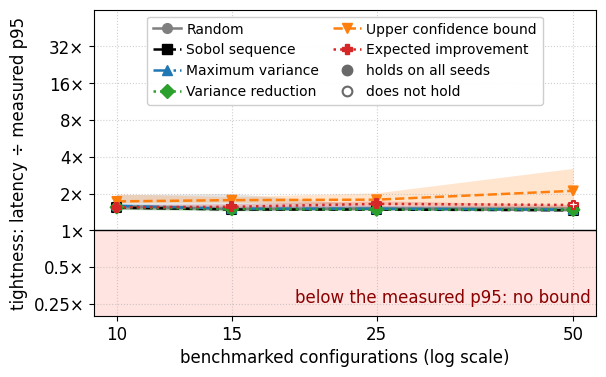

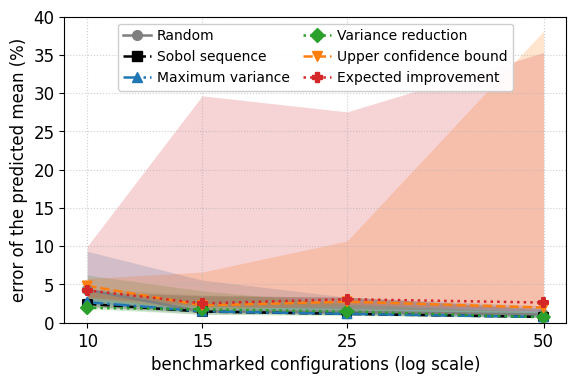

In [6]:
explore_statistics = sweep_statistics(explore_bounds, explore_truth, explore_sizes, seeds, confidence)   # strategy -> coverage, tightness, holds, computed
exploration_figure(explore_sizes, explore_statistics, explore_error,
                   f"B.2b sampling strategies, synthetic data: {' → '.join(synthetic_bases[seeds[0]].path)}, Pegasus Node, {len(seeds)} seeds", p_label,
                   name="b2b_sampling_strategies_synthetic")

In [7]:
explore_label = lambda size: f"{size} benchmarks"
error_at = lambda strategy, size: np.median(explore_error[strategy][explore_sizes.index(size)])   # median over the seeds
lowest_coverage = lambda strategy, size: explore_statistics[strategy]["coverage"][explore_sizes.index(size)].min()
display(Markdown(
    f"**What this shows** (synthetic data, Pegasus Node, ε = {alpha:g}, {len(seeds)} seeds).\n"
    + sweep_conclusion(explore_sizes, explore_statistics, list(STRATEGIES), explore_label)
    + "\n- **Error of the predicted mean execution time** (median over the seeds) with "
    + " and ".join(explore_label(size) for size in (explore_sizes[0], explore_sizes[-1])) + ": "
    + "; ".join(f"{strategy} {error_at(strategy, explore_sizes[0]):.1%} and {error_at(strategy, explore_sizes[-1]):.1%}" for strategy in STRATEGIES)
    + ".\n- **Lowest coverage over the seeds** with " + explore_label(explore_sizes[0]) + ": "
    + ", ".join(f"{strategy} {lowest_coverage(strategy, explore_sizes[0]):.2f}" for strategy in STRATEGIES)
    + f". The level to reach is {confidence:.2f}."
))

**What this shows** (synthetic data, Pegasus Node, ε = 0.05, 3 seeds).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Random, Sobol sequence, Maximum variance, Variance reduction, Upper confidence bound. Methods that do not hold, and where: Expected improvement at 50 benchmarks.
- **Tightness among the methods that hold** (median over the seeds): Random from 1.58× at 10 benchmarks to 1.46× at 50 benchmarks; Sobol sequence from 1.53× at 10 benchmarks to 1.46× at 50 benchmarks; Maximum variance from 1.59× at 10 benchmarks to 1.48× at 50 benchmarks; Variance reduction from 1.55× at 10 benchmarks to 1.47× at 50 benchmarks; Upper confidence bound from 1.73× at 10 benchmarks to 2.11× at 50 benchmarks.
- **Error of the predicted mean execution time** (median over the seeds) with 10 benchmarks and 50 benchmarks: Random 4.3% and 1.1%; Sobol sequence 2.5% and 0.8%; Maximum variance 2.7% and 0.7%; Variance reduction 1.9% and 0.7%; Upper confidence bound 4.8% and 2.0%; Expected improvement 4.2% and 2.6%.
- **Lowest coverage over the seeds** with 10 benchmarks: Random 1.00, Sobol sequence 1.00, Maximum variance 1.00, Variance reduction 1.00, Upper confidence bound 1.00, Expected improvement 1.00. The level to reach is 0.95.

**Setting (real data; skipped, see above).** The chain, the held-out runs and the ground truth of the real B.1 of the first
campaign (qr → cv → face), for every seed. What differs from the
synthetic part:
- A *benchmark* is one measured run of one service, with the mean and the spread of its processing times (see Training
  data in B.1). A strategy *selects* it from the runs that may train the service: its runs alone and in pipelines of
  another topology, several hundred per service. It sees the configurations of all these runs, and the processing
  times only of the runs it has selected.
- Every service selects its own runs, because the real services have their own knobs; after $n$ selections per
  service, the models are fitted as in B.2.
- The adaptive strategies use the mean model of the real data, a GP on the logarithm of the run means. Their scores
  are therefore relative: the upper confidence bound prefers runs that are slow or uncertain by a factor, and the
  expected improvement is an improvement of the logarithm of the mean processing time.
- A fixed set of runs has no Sobol sequence. Its counterpart is *farthest point*: after the initial random runs, always
  the run whose configuration is farthest from the configurations selected so far (in standardized knobs). Like the
  Sobol sequence, it spreads the runs over the space without looking at a model.

The figure is the one of the synthetic part, with the number of selected runs per service on the horizontal axis. A
strategy has no point where, for half of the seeds or more, the bound is infinite at half of the held-out runs or
more.

In [8]:
if "B.2b real" in skipped:
    print("B.2b real skipped: not supported by the {} data".format(data_source))
else:
    # B.2b, real data: every service selects its training runs one by one among its measured runs (real_exploration_results in
    # pegasus/exploration.py). This cell imports what it needs itself, so nothing above has to be run again.
    from pegasus.exploration import POOL_STRATEGIES, real_exploration_results

    explore_experiment = "04e-chain-qr-cv-face"   # the real chain of B.1
    real_bases = bases if data_source == "real" else {
        s: load_chain_data("real", experiment=explore_experiment, utilization=0.5, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s]) for s in seeds}
    pool_bounds, pool_truth = {}, {}                                                                    # (size, seed) -> strategy -> ("proposed", latency per held-out run) / truth
    pool_error = {strategy: np.empty((len(explore_sizes), len(seeds))) for strategy in POOL_STRATEGIES}   # relative error of the predicted mean
    with warnings.catch_warnings():
        # with few runs the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for j, s in enumerate(seeds):
            for strategy in POOL_STRATEGIES:
                results = real_exploration_results(explore_experiment, real_bases[s], strategy, explore_sizes, n_initial, seed=[seed, s, 300], alpha=alpha,
                                                   confidence=confidence, model_seed=seed + s)
                for i, size in enumerate(explore_sizes):
                    pool_bounds.setdefault((size, s), {})[strategy] = ("proposed", results[size][0])
                    pool_truth[(size, s)] = (real_bases[s].measured, real_bases[s].measured_low)
                    pool_error[strategy][i, j] = results[size][1]
    print(f"{len(POOL_STRATEGIES)} strategies evaluated for {len(seeds)} seeds.")

B.2b real skipped: not supported by the real data


In [9]:
if "B.2b real" in skipped:
    print("B.2b real skipped: not supported by the {} data".format(data_source))
else:
    pool_statistics = sweep_statistics(pool_bounds, pool_truth, explore_sizes, seeds, confidence)   # strategy -> coverage, tightness, holds, computed
    exploration_figure(explore_sizes, pool_statistics, pool_error,
                       f"B.2b sampling strategies, real data: {' → '.join(real_bases[seeds[0]].path)}, Pegasus Node, {len(seeds)} seeds", p_label,
                       xlabel="selected runs per service (log scale)", name="b2b_sampling_strategies_real")

B.2b real skipped: not supported by the real data


In [10]:
if "B.2b real" in skipped:
    print("B.2b real skipped: not supported by the {} data".format(data_source))
else:
    pool_label = lambda size: f"{size} selected runs"
    pool_error_at = lambda strategy, size: np.median(pool_error[strategy][explore_sizes.index(size)])   # median over the seeds
    pool_lowest = lambda strategy, size: pool_statistics[strategy]["coverage"][explore_sizes.index(size)].min()
    display(Markdown(
        f"**What this shows** (real data, Pegasus Node, ε = {alpha:g}, {len(seeds)} seeds).\n"
        + sweep_conclusion(explore_sizes, pool_statistics, list(POOL_STRATEGIES), pool_label)
        + "\n- **Error of the predicted mean execution time** (median over the seeds) with "
        + " and ".join(pool_label(size) for size in (explore_sizes[0], explore_sizes[-1])) + ": "
        + "; ".join(f"{strategy} {pool_error_at(strategy, explore_sizes[0]):.1%} and {pool_error_at(strategy, explore_sizes[-1]):.1%}" for strategy in POOL_STRATEGIES)
        + ".\n- **Finite bounds.** Share of the held-out runs with a finite bound (median over the seeds) with "
        + " and ".join(pool_label(size) for size in (explore_sizes[0], explore_sizes[-1])) + ": "
        + "; ".join(f"{strategy} {finite_share(pool_bounds, strategy, explore_sizes[0], seeds):.0%} and {finite_share(pool_bounds, strategy, explore_sizes[-1], seeds):.0%}"
                    for strategy in POOL_STRATEGIES)
        + ".\n- **Lowest coverage over the seeds** with " + pool_label(explore_sizes[0]) + ": "
        + ", ".join(f"{strategy} {pool_lowest(strategy, explore_sizes[0]):.2f}" for strategy in POOL_STRATEGIES)
        + f". The level to reach is {confidence:.2f}."
    ))

B.2b real skipped: not supported by the real data
